# <font color="gold">0-3. Extract U Exeter University Review Data</font>

## <font color='cornflowerblue'>University review - Dataset Info</font>

-----------------------------------------
Category:  &ensp;&emsp; University review  
Source:    &ensp; &ensp;&ensp; &ensp;  Rohit Pawar (2023) - University of Exeter Reviews    (N = 557)   
URL:     &ensp; &ensp; &ensp; &ensp;  &ensp;  https://www.kaggle.com/datasets/rohitpawar1/university-of-exeter-reviews    
Lisence:  &ensp; &ensp; &ensp;  CC0: Public Domain  

“This Data contains Reviews of University of Exeter, UK from www.studentcrowd.com with Ratings. ...  The dataset contains information about the date review was added, the review itself added by the student, overall rating, and other ratings like Facilities, Wifi, Societies, etc of the university”

-----------------------------------------

In [1]:
import pandas as pd

file = '../../data/0_raw/data3_UExeter_uni_reviews.csv' 

outfilename = '../../data/1_processed/3_UExeter_uni_reviews.csv'

print(f'Input: \n          {file}\n\nOutput:   {outfilename}')

Input: 
          ../../data/0_raw/data3_UExeter_uni_reviews.csv

Output:   ../../data/1_processed/3_UExeter_uni_reviews.csv


In [2]:
output = pd.read_csv(file, dtype=str)

print(len(output))
output = output.drop_duplicates(keep='first')
print(len(output))

output


557
557


,Member ID,Date,Review,Student Review,Campus/Facilities,Club/Societies,Careers Service,Wifi/Internet
0,887111,1st June 23,I like my university very much!,5,5,5,5,5
1,1287025,31st May 23,"I am from the USA, so I am comparing my experi...",3.4,3,3,3,5
2,1286468,20th May 23,Exeter University is generally a lovely place ...,4,5,4,4,3
3,486467,20th May 23,Nice facilities and some great lecturers! The ...,4.4,4,4,4,5
4,486456,19th May 23,The uni is good they provide me with alot of s...,4.8,5,5,5,5
...,...,...,...,...,...,...,...,...
552,NaN,25th March 15,Brilliant university; beautiful campus; active...,4.7,5,5,5,5
553,NaN,25th March 15,Sport membership is very expensive,4.3,4,5,5,5
554,NaN,25th March 15,It is great! But there should be a swimming po...,4.3,4,5,5,5
555,NaN,25th March 15,ITS AMAZING! I love my university and wouldn't...,4.7,5,5,5,5


In [3]:
output = output.rename(columns={'Member ID':'student_id', 'Date':'date', 'Review':'review_text', 
                                'Student Review':'rating_overall','Campus/Facilities':'rating_facilities', 'Club/Societies':'rating_clubs', 
                                'Careers Service':'rating_careerService', 'Wifi/Internet':'rating_internet'}).fillna('')

print(len(output), len(output.student_id.unique()))

print(list(output.columns.values)) 

output

557 528
['student_id', 'date', 'review_text', 'rating_overall', 'rating_facilities', 'rating_clubs', 'rating_careerService', 'rating_internet']


,student_id,date,review_text,rating_overall,rating_facilities,rating_clubs,rating_careerService,rating_internet
0,887111,1st June 23,I like my university very much!,5,5,5,5,5
1,1287025,31st May 23,"I am from the USA, so I am comparing my experi...",3.4,3,3,3,5
2,1286468,20th May 23,Exeter University is generally a lovely place ...,4,5,4,4,3
3,486467,20th May 23,Nice facilities and some great lecturers! The ...,4.4,4,4,4,5
4,486456,19th May 23,The uni is good they provide me with alot of s...,4.8,5,5,5,5
...,...,...,...,...,...,...,...,...
552,,25th March 15,Brilliant university; beautiful campus; active...,4.7,5,5,5,5
553,,25th March 15,Sport membership is very expensive,4.3,4,5,5,5
554,,25th March 15,It is great! But there should be a swimming po...,4.3,4,5,5,5
555,,25th March 15,ITS AMAZING! I love my university and wouldn't...,4.7,5,5,5,5


In [4]:
output.filter(regex='rating_|rating$').drop_duplicates(keep='first')

,rating_overall,rating_facilities,rating_clubs,rating_careerService,rating_internet
0,5,5,5,5,5
1,3.4,3,3,3,5
2,4,5,4,4,3
3,4.4,4,4,4,5
4,4.8,5,5,5,5
...,...,...,...,...,...
539,4.3,4,5,5,5
540,4.3,5,4,5,5
545,3.7,3,5,4,3
548,4.5,5,5,5,5


In [5]:
output.loc[output.rating_overall.str.len()==0]

,student_id,date,review_text,rating_overall,rating_facilities,rating_clubs,rating_careerService,rating_internet


In [6]:
output.loc[output.student_id.str.len()==0]

,student_id,date,review_text,rating_overall,rating_facilities,rating_clubs,rating_careerService,rating_internet
527,,1st July 15,Despite a very difficult start at Exeter due t...,4.2,4,4,5,5
528,,12th April 15,Amazing sport facilities and friendly atmosphe...,4.5,4,5,5,5
529,,30th March 15,My first year at Exeter has been one of the be...,4.7,5,5,5,5
530,,29th March 15,Been at Exeter Uni for 2 years now and I've lo...,4.7,5,5,5,5
531,,29th March 15,A lot of pressure is put on career opportuniti...,2.5,2,3,4,1
532,,28th March 15,"Great university, amazing facilities and beaut...",4.2,5,4,4,5
533,,28th March 15,Campus is beautiful! There's a wide range of s...,3.8,5,4,4,4
534,,28th March 15,Exeter offers the best in every single respect...,4.5,5,5,5,4
535,,27th March 15,One of my lecturers is a PhD student who cares...,3.2,3,3,3,3
536,,27th March 15,Probably the best university in the world,4.2,5,5,2,5


557


,rating_overall,count
4,1.0,4
3,2.0,6
2,3.0,44
1,4.0,187
0,5.0,316


<Axes: xlabel='Count', ylabel='rating_overall'>

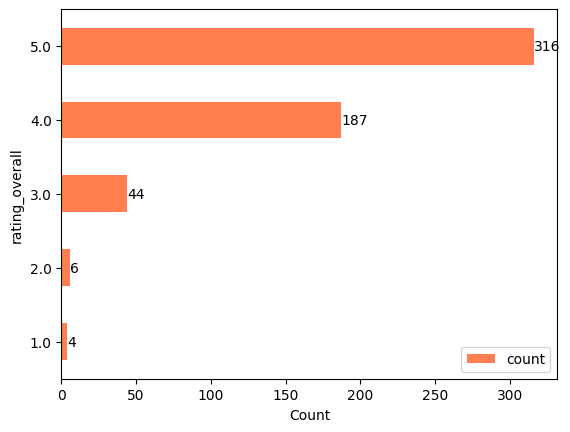

In [7]:
rating_df = output.rating_overall.astype('float64').round(0).value_counts().reset_index().sort_values(by='rating_overall', ascending=True)
print(rating_df['count'].sum())
display(rating_df)

ax1 = rating_df.plot.barh(x='rating_overall', y='count', xlabel='Count', color='coral', table=False)
ax1.bar_label(ax1.containers[0]) 
ax1

In [8]:
print(len(output))
output = output.loc[(output.review_text.str.len() > 0) & (~output.review_text.str.lower().isin(['no comment', 'no comments'])) & (~output.review_text.str.fullmatch(r'([.]+|[,]+)'))]
print(len(output))

output

557
557


,student_id,date,review_text,rating_overall,rating_facilities,rating_clubs,rating_careerService,rating_internet
0,887111,1st June 23,I like my university very much!,5,5,5,5,5
1,1287025,31st May 23,"I am from the USA, so I am comparing my experi...",3.4,3,3,3,5
2,1286468,20th May 23,Exeter University is generally a lovely place ...,4,5,4,4,3
3,486467,20th May 23,Nice facilities and some great lecturers! The ...,4.4,4,4,4,5
4,486456,19th May 23,The uni is good they provide me with alot of s...,4.8,5,5,5,5
...,...,...,...,...,...,...,...,...
552,,25th March 15,Brilliant university; beautiful campus; active...,4.7,5,5,5,5
553,,25th March 15,Sport membership is very expensive,4.3,4,5,5,5
554,,25th March 15,It is great! But there should be a swimming po...,4.3,4,5,5,5
555,,25th March 15,ITS AMAZING! I love my university and wouldn't...,4.7,5,5,5,5


In [9]:
output.loc[output.review_text.str.fullmatch(r'([.]+|[,]+)')]

,student_id,date,review_text,rating_overall,rating_facilities,rating_clubs,rating_careerService,rating_internet


557


,rating_overall,count
4,1.0,4
3,2.0,6
2,3.0,44
1,4.0,187
0,5.0,316


<Axes: xlabel='Count', ylabel='rating_overall'>

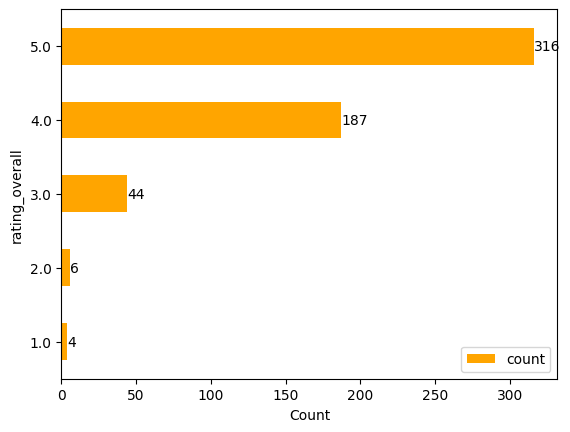

In [10]:
overall_ratingdf = output.rating_overall.astype('float64').round(0).value_counts().reset_index().sort_values(by='rating_overall', ascending=True)

print(overall_ratingdf['count'].sum())
display(overall_ratingdf)

ax3 = overall_ratingdf.plot.barh(x='rating_overall', y='count', xlabel='Count', color='orange', table=False)
ax3.bar_label(ax3.containers[0]) 
ax3

## <font color='gold'>Make unique IDs</font>

In [11]:
output = output.reset_index()
output.loc[:,'source'] = f'data3_{len(output)}'
output

,index,student_id,date,review_text,rating_overall,rating_facilities,rating_clubs,rating_careerService,rating_internet,source
0,0,887111,1st June 23,I like my university very much!,5,5,5,5,5,data3_557
1,1,1287025,31st May 23,"I am from the USA, so I am comparing my experi...",3.4,3,3,3,5,data3_557
2,2,1286468,20th May 23,Exeter University is generally a lovely place ...,4,5,4,4,3,data3_557
3,3,486467,20th May 23,Nice facilities and some great lecturers! The ...,4.4,4,4,4,5,data3_557
4,4,486456,19th May 23,The uni is good they provide me with alot of s...,4.8,5,5,5,5,data3_557
...,...,...,...,...,...,...,...,...,...,...
552,552,,25th March 15,Brilliant university; beautiful campus; active...,4.7,5,5,5,5,data3_557
553,553,,25th March 15,Sport membership is very expensive,4.3,4,5,5,5,data3_557
554,554,,25th March 15,It is great! But there should be a swimming po...,4.3,4,5,5,5,data3_557
555,555,,25th March 15,ITS AMAZING! I love my university and wouldn't...,4.7,5,5,5,5,data3_557


In [12]:
idcols = ['source', 'index', 'student_id', 'date']

for each in idcols:
    if each == 'source':
        output.loc[:,f'{each}_rank'] = output.source.str[4]
    else:
        output.loc[:,f'{each}_rank'] = output[each].rank(method='dense').astype(int)
        
output

,index,student_id,date,review_text,rating_overall,rating_facilities,rating_clubs,rating_careerService,rating_internet,source,source_rank,index_rank,student_id_rank,date_rank
0,0,887111,1st June 23,I like my university very much!,5,5,5,5,5,data3_557,3,1,469,129
1,1,1287025,31st May 23,"I am from the USA, so I am comparing my experi...",3.4,3,3,3,5,data3_557,3,2,161,233
2,2,1286468,20th May 23,Exeter University is generally a lovely place ...,4,5,4,4,3,data3_557,3,3,160,142
3,3,486467,20th May 23,Nice facilities and some great lecturers! The ...,4.4,4,4,4,5,data3_557,3,4,273,142
4,4,486456,19th May 23,The uni is good they provide me with alot of s...,4.8,5,5,5,5,data3_557,3,5,272,119
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
552,552,,25th March 15,Brilliant university; beautiful campus; active...,4.7,5,5,5,5,data3_557,3,553,1,182
553,553,,25th March 15,Sport membership is very expensive,4.3,4,5,5,5,data3_557,3,554,1,182
554,554,,25th March 15,It is great! But there should be a swimming po...,4.3,4,5,5,5,data3_557,3,555,1,182
555,555,,25th March 15,ITS AMAZING! I love my university and wouldn't...,4.7,5,5,5,5,data3_557,3,556,1,182


In [13]:
output.insert(loc=0, column='id', value=output.filter(regex='_rank').map(str).apply('_'.join, axis=1))
output.loc[:,'type'] = 'university review'

if len(output.id.unique())==len(output):
    print("\033[32mAll good!\n\033[0m")
    output = output.drop(columns=[i for i in output.columns.values if '_rank' in i])
else:
    display(output.loc[output.id.duplicated(keep='first')].sort_values(by='id'))
    raise ValueError("ids not unique, check!!!!")

output

All good!



,id,index,student_id,date,review_text,rating_overall,rating_facilities,rating_clubs,rating_careerService,rating_internet,source,type
0,3_1_469_129,0,887111,1st June 23,I like my university very much!,5,5,5,5,5,data3_557,university review
1,3_2_161_233,1,1287025,31st May 23,"I am from the USA, so I am comparing my experi...",3.4,3,3,3,5,data3_557,university review
2,3_3_160_142,2,1286468,20th May 23,Exeter University is generally a lovely place ...,4,5,4,4,3,data3_557,university review
3,3_4_273_142,3,486467,20th May 23,Nice facilities and some great lecturers! The ...,4.4,4,4,4,5,data3_557,university review
4,3_5_272_119,4,486456,19th May 23,The uni is good they provide me with alot of s...,4.8,5,5,5,5,data3_557,university review
...,...,...,...,...,...,...,...,...,...,...,...,...
552,3_553_1_182,552,,25th March 15,Brilliant university; beautiful campus; active...,4.7,5,5,5,5,data3_557,university review
553,3_554_1_182,553,,25th March 15,Sport membership is very expensive,4.3,4,5,5,5,data3_557,university review
554,3_555_1_182,554,,25th March 15,It is great! But there should be a swimming po...,4.3,4,5,5,5,data3_557,university review
555,3_556_1_182,555,,25th March 15,ITS AMAZING! I love my university and wouldn't...,4.7,5,5,5,5,data3_557,university review


In [14]:
output.loc[output.student_id =='']

,id,index,student_id,date,review_text,rating_overall,rating_facilities,rating_clubs,rating_careerService,rating_internet,source,type
527,3_528_1_126,527,,1st July 15,Despite a very difficult start at Exeter due t...,4.2,4,4,5,5,data3_557,university review
528,3_529_1_28,528,,12th April 15,Amazing sport facilities and friendly atmosphe...,4.5,4,5,5,5,data3_557,university review
529,3_530_1_226,529,,30th March 15,My first year at Exeter has been one of the be...,4.7,5,5,5,5,data3_557,university review
530,3_531_1_214,530,,29th March 15,Been at Exeter Uni for 2 years now and I've lo...,4.7,5,5,5,5,data3_557,university review
531,3_532_1_214,531,,29th March 15,A lot of pressure is put on career opportuniti...,2.5,2,3,4,1,data3_557,university review
532,3_533_1_205,532,,28th March 15,"Great university, amazing facilities and beaut...",4.2,5,4,4,5,data3_557,university review
533,3_534_1_205,533,,28th March 15,Campus is beautiful! There's a wide range of s...,3.8,5,4,4,4,data3_557,university review
534,3_535_1_205,534,,28th March 15,Exeter offers the best in every single respect...,4.5,5,5,5,4,data3_557,university review
535,3_536_1_195,535,,27th March 15,One of my lecturers is a PhD student who cares...,3.2,3,3,3,3,data3_557,university review
536,3_537_1_195,536,,27th March 15,Probably the best university in the world,4.2,5,5,2,5,data3_557,university review


<br>

## <font color='gold'>Write output</font>

In [15]:
print(output.shape)
output.to_csv(outfilename, index=True)
print(f'\n\033[33mCombined file written to {outfilename} :)\n')

(557, 12)

Combined file written to ../../data/1_processed/3_UExeter_uni_reviews.csv :)

